In [1]:
%load_ext autoreload
%autoreload 2

**Change the working directory to the `target_folder`, which should be the parent folder of `code`, `config`, `data`, `results` and `test`.**

In [2]:
import os
import os
import sys
import numpy as np
import pandas as pd

# Add the project root to the PYTHONPATH
script_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(script_dir, '..'))
sys.path.append(project_root)

In [3]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src_utils.utils import load_and_preprocess_data as get_data
from src_utils.WM_network import WorkingMemoryNetwork
from config.WM_params import WorkingMemoryParameters

random_seed = 666
outside_rng = np.random.default_rng(random_seed)

## Load data

In [4]:
data = get_data('../../../data')
area_names = data['area_names']
area_lobes = data['area_lobes']
area_descriptions = data['area_descriptions']
F = data['SLN']
W = data['W']
h = data['hier_vals']

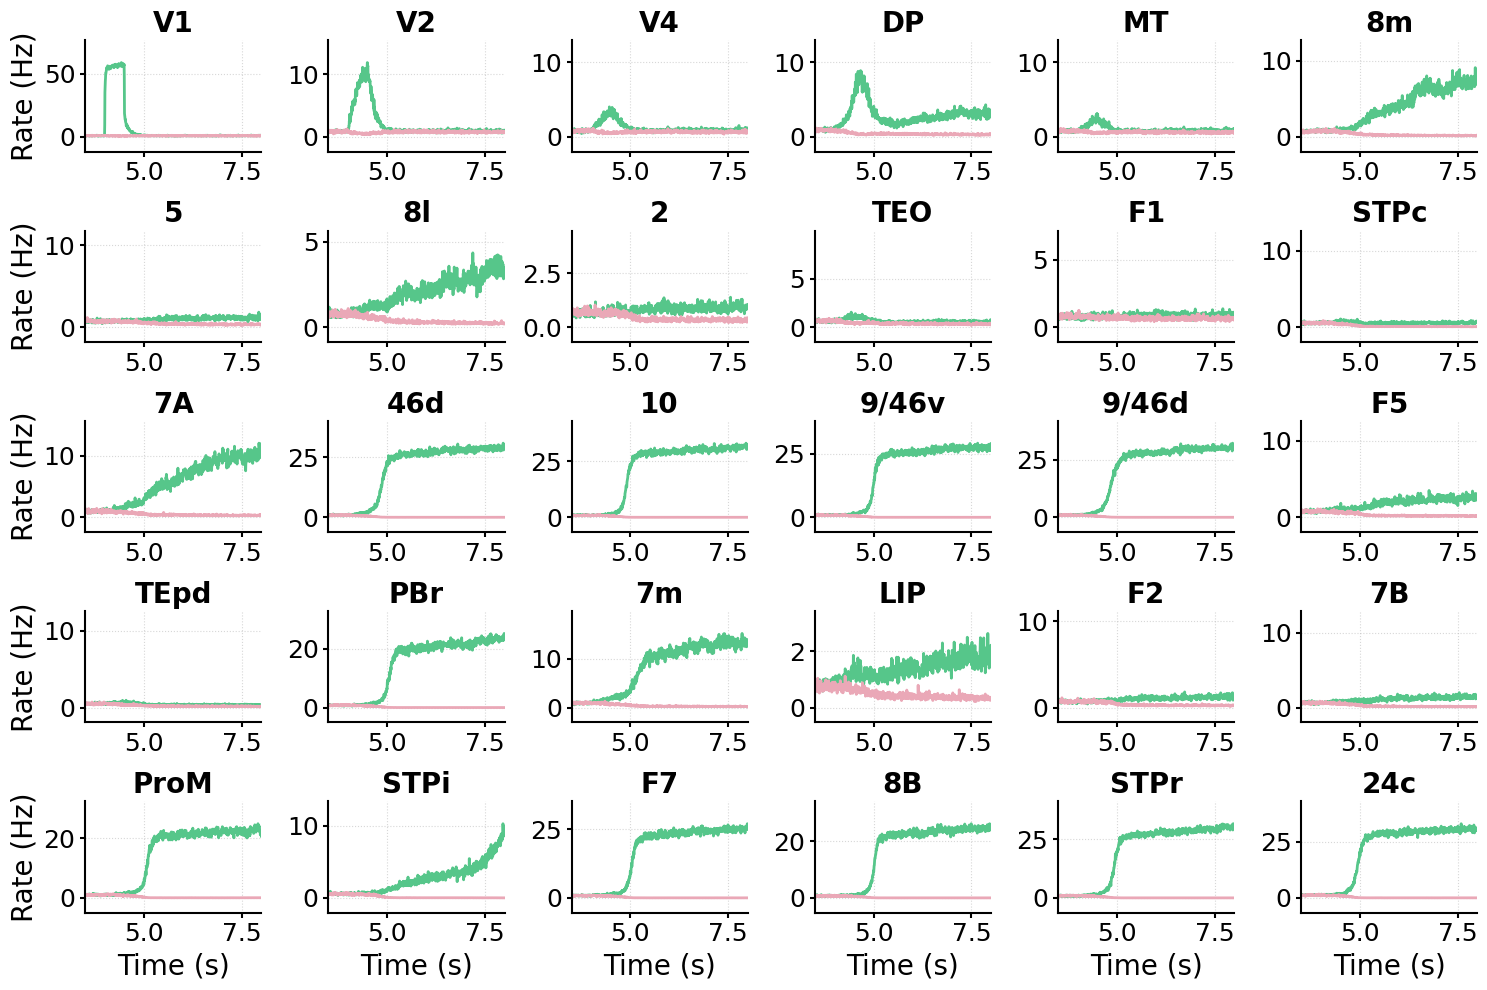

In [5]:
# Initial condition and parameters
N = len(area_names)
Y0 = np.zeros((N, 8))
Y0[:, 0:3] = 5 * (1 + np.tanh(outside_rng.normal(0, 2, (N, 3)))) # r values are initialized randomly between 0 and 10
WM_params = WorkingMemoryParameters()
WM_params.update(G=0.58, J_MAX=0.42)
# Generate the network
WM_network = WorkingMemoryNetwork(area_names=area_names, area_lobes=area_lobes, Y0=Y0, W=W, F=F, h=h, params=WM_params)

# Run the simulation
t_end = 8
dt = 0.5e-3
I_ext_strength = np.zeros((N, 3))
I_ext_strength[0, 0] = 0.3
state_history = WM_network.run(t_end=t_end, dt=dt, I_ext_strengths=np.array([I_ext_strength]), ts_ext_start=np.array([4]), ts_ext_end=np.array([4.5]))

# Plot the results
_ = WM_network.plot_all_areas(xlim=(3.5, t_end), colors=['#56c68a', '#eaa8b7'],
                              save_path='../results/all_areas_traces.pdf', legend=False)

## Journal-sized version of the all-areas figure

The same traces `plot_all_areas` draws above, redrawn as one 5 x 6 grid at an exact physical size:
2/3 of the 18.4 cm page width by 9 cm, Open Sans at 7 pt, matching the panels of the `Figures/`
notebooks. Reuses `WM_network` from the cell above, so run that first. Nothing above is modified:
the styling is applied only inside the `mpl.rc_context` block.

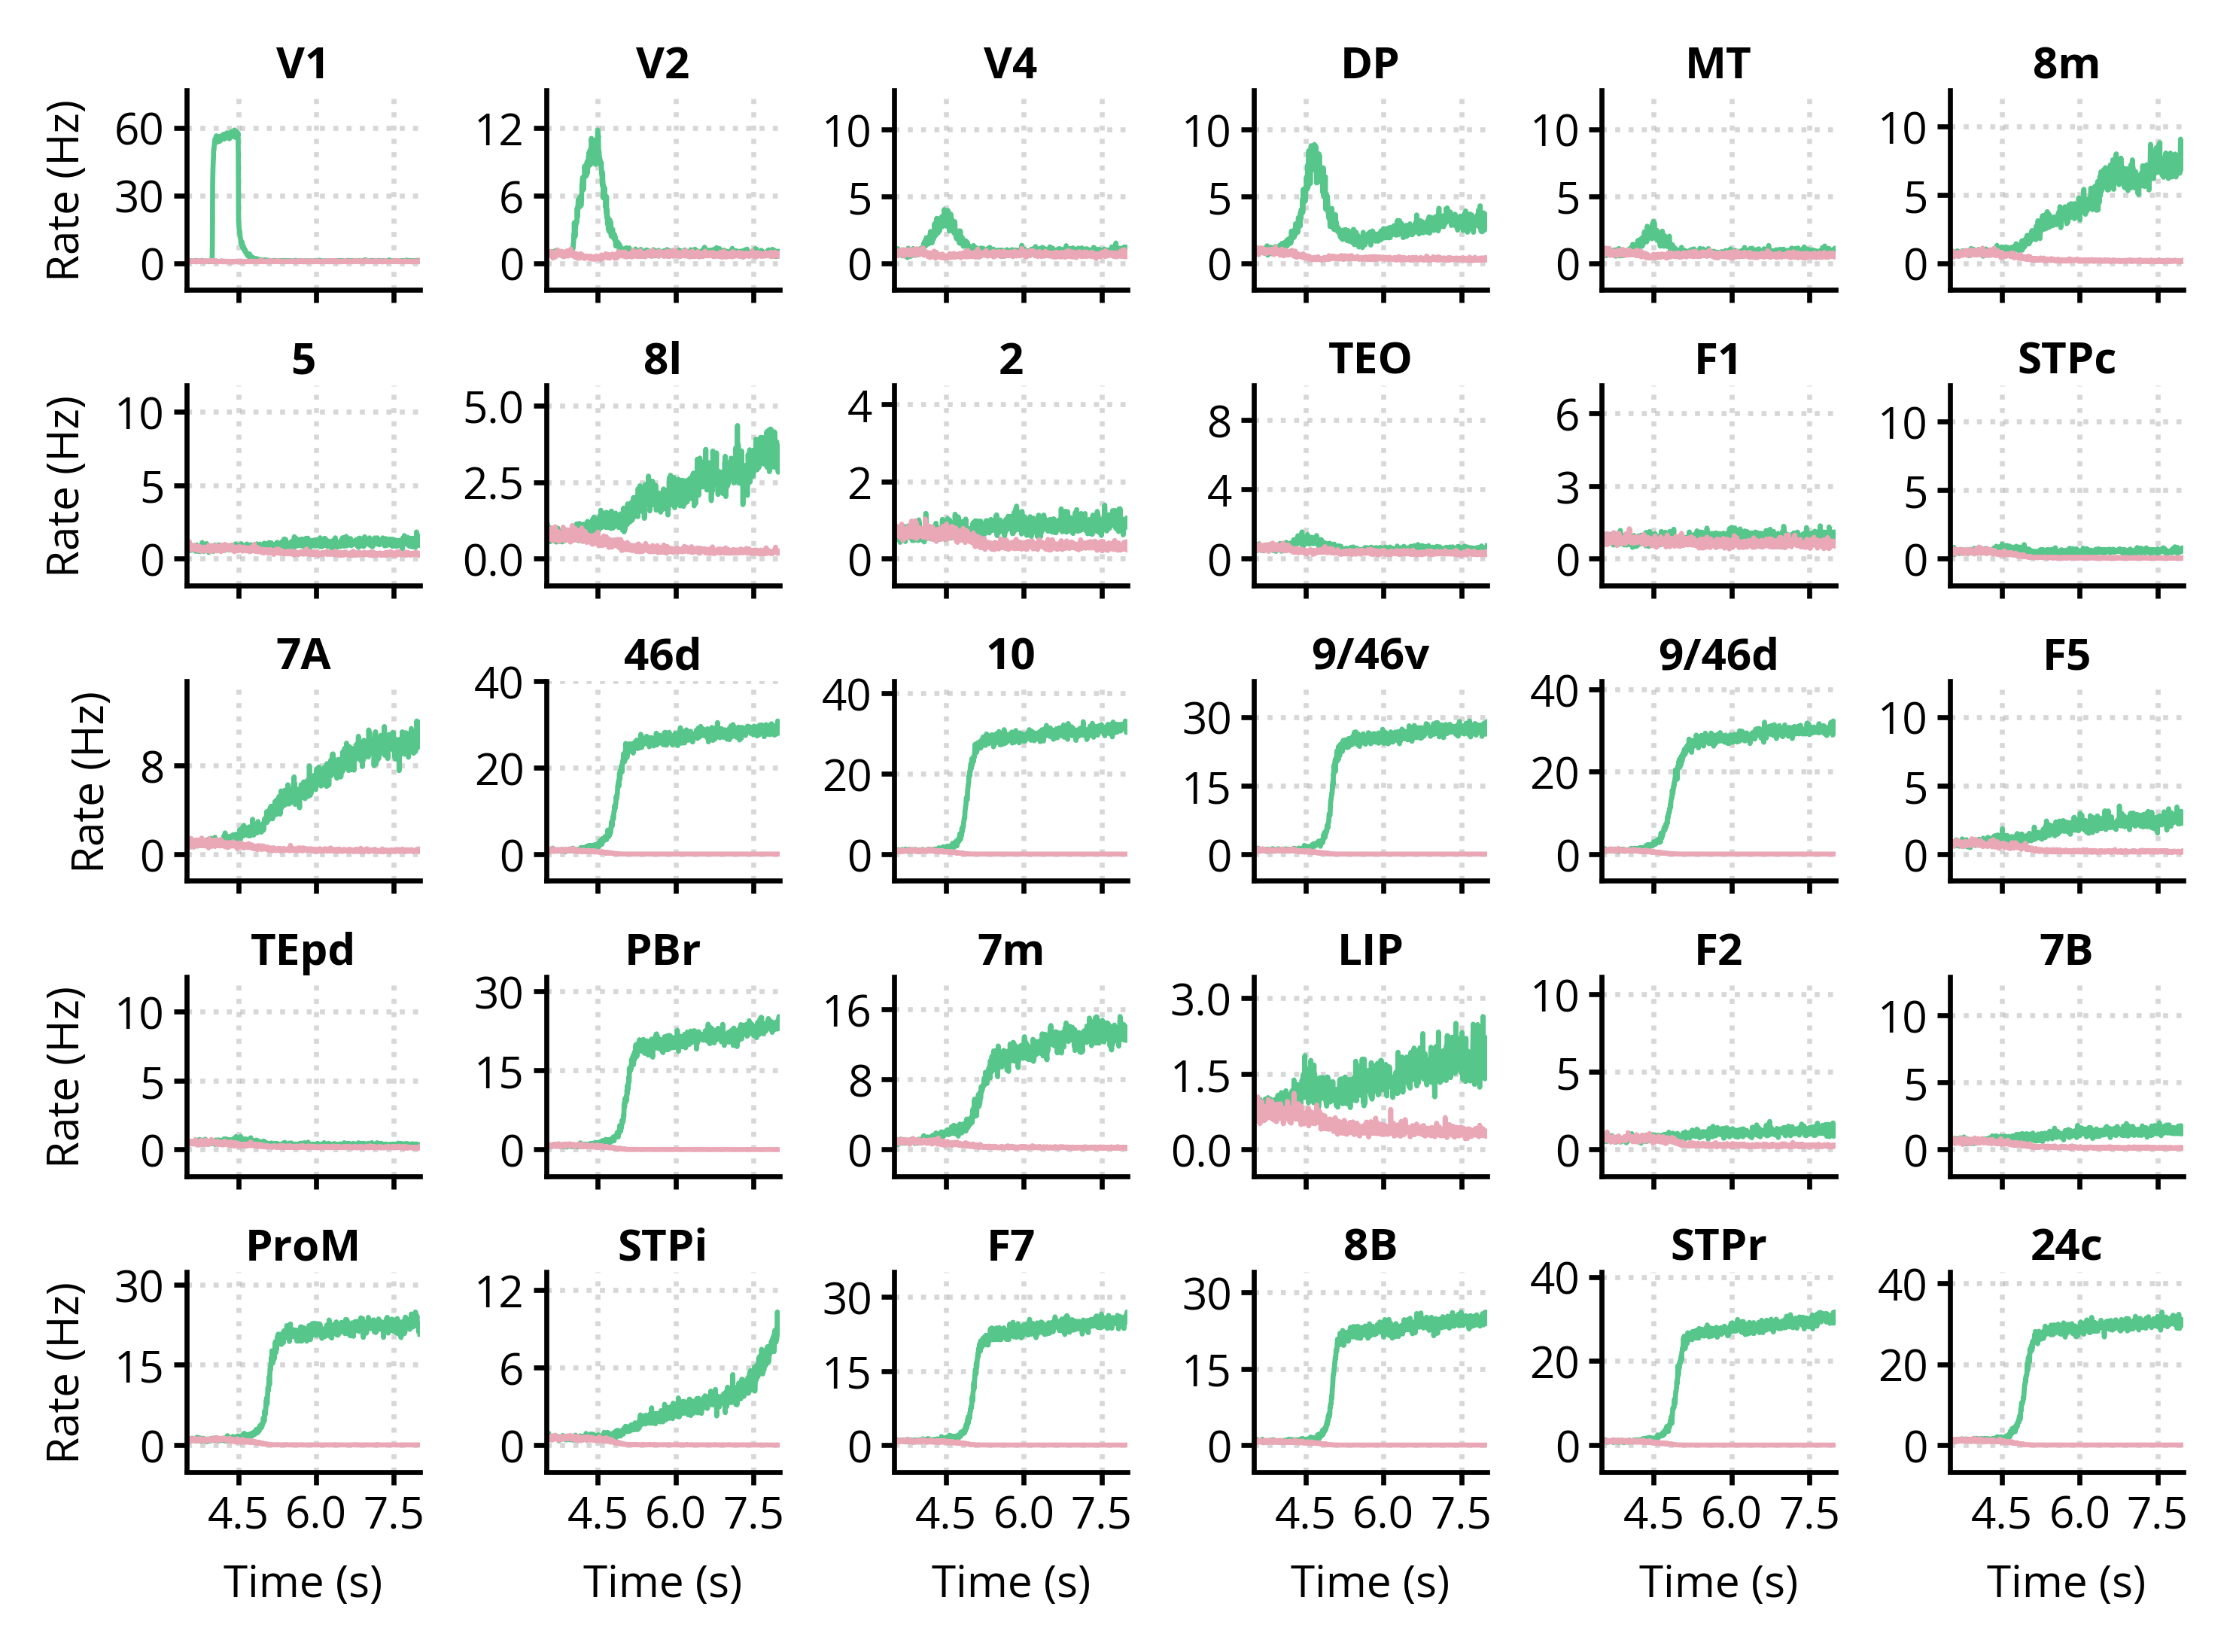

Panel is 12.27 x 9.00 cm, 5 x 6 grid for 30 areas


In [6]:
# Journal-sized version of the all-areas figure: one 5 x 6 grid of the 30 areas,
# 2/3 of the 18.4 cm page width by 9 cm, Open Sans at 7 pt.
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Same style dict as the assembled panels in the Figures/ notebooks. Applied only inside
# the "with" block below, so the rcParams used by plot_all_areas are left alone.
# Note: if the 'science' style is ever active it sets text.usetex = True, and LaTeX ignores
# font.family, so usetex has to be off for Open Sans to actually be used.
panel_style = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

variables = ['r_A', 'r_B']
pop_colors = ['#56c68a', '#eaa8b7']   # same colours as the plot_all_areas call above
downsample = 10
NCOLS = 6                              # plot_all_areas also uses 6 columns

# Same data and time axis plot_all_areas uses internally
state_history_panel = WM_network.get_state_histories(variables)[-1]  # (n_timepoints, n_areas, n_vars)
t_down = WM_network.time_histories[-1][::downsample]

# figsize is in inches, so divide the cm by 2.54
CM = 2.54
FIG_W = 2 / 3 * 18.4 / CM
FIG_H = 9.0 / CM                       # 8 cm is very tight for five rows, 9 cm reads better

nrows = int(np.ceil(WM_network.N / NCOLS))

with mpl.rc_context(panel_style):
    # sharex: every area has the same time axis, so only the bottom row needs tick labels.
    # y is NOT shared: the areas differ by more than an order of magnitude in rate, and
    # plot_all_areas also scales each panel to its own maximum.
    fig, axes = plt.subplots(nrows, NCOLS, figsize=(FIG_W, FIG_H),
                             constrained_layout=True, sharex=True)
    axes = axes.flatten()

    for i, ax in enumerate(axes[:WM_network.N]):
        ymax = 0
        for var_idx, var in enumerate(variables):
            data = state_history_panel[:, i, var_idx][::downsample]
            ax.plot(t_down, data, color=pop_colors[var_idx], linewidth=0.8)
            ymax = max(ymax, data.max())

        ax.set_title(WM_network.area_names[i], fontweight='bold', pad=2)
        ax.set_xlim(3.5, t_end)
        # same per-panel y range as plot_all_areas
        ax.set_ylim(-max(ymax * 0.2, 0.5), max(ymax * 1.3, 2))

        ax.minorticks_off()
        ax.xaxis.set_major_locator(MaxNLocator(3))
        ax.yaxis.set_major_locator(MaxNLocator(3))
        ax.grid(linestyle=':', alpha=0.5)
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')
        # set_ticks_position turns the tick labels back on, undoing sharex, so the
        # inner x tick labels have to be switched off again by hand
        ax.tick_params(labelbottom=(i >= (nrows - 1) * NCOLS), pad=1.5)

        # axis labels only on the outer panels, they would not fit on all thirty
        if i % NCOLS == 0:
            ax.set_ylabel('Rate (Hz)')
        if i >= (nrows - 1) * NCOLS:
            ax.set_xlabel('Time (s)')

    # drop the unused panels if N is not a multiple of NCOLS
    for ax in axes[WM_network.N:]:
        fig.delaxes(ax)

    # no bbox_inches='tight', so the files keep the exact 12.27 x 9 cm size
    fig.savefig('../results/all_areas_traces_journal.svg')
    fig.savefig('../results/all_areas_traces_journal.pdf')
    plt.show()

print(f'Panel is {FIG_W * CM:.2f} x {FIG_H * CM:.2f} cm, {nrows} x {NCOLS} grid for {WM_network.N} areas')
